# Data Overview

A descriptive look at the creativity ratings before the model-based analysis:
how much data there is, how it is distributed across actions and raters, how
well connected the rater-action design is, and the raters' response styles.

This notebook reads the preprocessed data produced by
`00_data_loading_preprocessing.ipynb` (`data/processed/ratings_long_clean.csv`).
The scoring and reliability analysis is the JRT graded response model in
`../R/` (see `../AUDIT.md`); the checked design tables used by the models
(category use per rater, rater overlap, connectivity) are written by
`../R/01_data_design.R`.

## 1. Load the preprocessed data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from IPython.display import Markdown

def show_table(df_table, digits=3):
    # Markdown table without the index column, for embedding in the manuscript.
    return Markdown(df_table.to_markdown(index=False, floatfmt=f".{digits}f"))

plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

PROJECT_ROOT = Path("..").resolve()
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

df = pd.read_csv(DATA_PROCESSED / "ratings_long_clean.csv")
df["action_id"] = df["action_id"].astype(str)
df["rater_id"] = df["rater_id"].astype(str)

print(f"Loaded {len(df)} ratings.")
df.head()

Loaded 7844 ratings.


,rater_id,action_id,rating,technical_correctness,aesthetic_appeal,timestamp,rating_numeric,rating_ordinal,rating_order
0,R04,0786bb62-2032-444b-ac1f-59fa165dbb71,1.0,2.0,2.0,2026-03-11 11:50:29.717,1,1,5
1,R03,f90addfa-4cf8-4b07-a4eb-9ee7ff757519,2.0,4.0,1.0,2025-11-18 12:26:15.275,2,2,708
2,R03,2bdc8133-ac12-45f1-9104-882873efa7bf,3.0,4.0,2.0,2025-10-15 13:35:18.000,3,3,17
3,R09,938d2c93-5e6f-442e-ba7c-f92c53080a42,5.0,5.0,5.0,2026-05-05 15:58:08.508,5,5,6
4,R04,4fe7a32b-09ce-466b-9772-494ed03ea493,6.0,7.0,7.0,2026-04-08 13:56:06.665,6,6,403


## 2. How much data do we have

Total number of ratings, and how many distinct actions and raters they
cover.

In [2]:
n_ratings = len(df)
n_actions = df["action_id"].nunique()
n_raters = df["rater_id"].nunique()

print(f"Total ratings:   {n_ratings}")
print(f"Distinct actions: {n_actions}")
print(f"Distinct raters:  {n_raters}")
print(f"Average ratings per action: {n_ratings / n_actions:.2f}")
print(f"Average ratings per rater:  {n_ratings / n_raters:.1f}")

Total ratings:   7844
Distinct actions: 3669
Distinct raters:  22
Average ratings per action: 2.14
Average ratings per rater:  356.5


## 3. Distribution of the number of ratings

Some actions have only one rating and contribute no within-action
agreement information; some raters have rated far more actions than
others. Both matter for how much we can trust the eventual reliability
estimates.

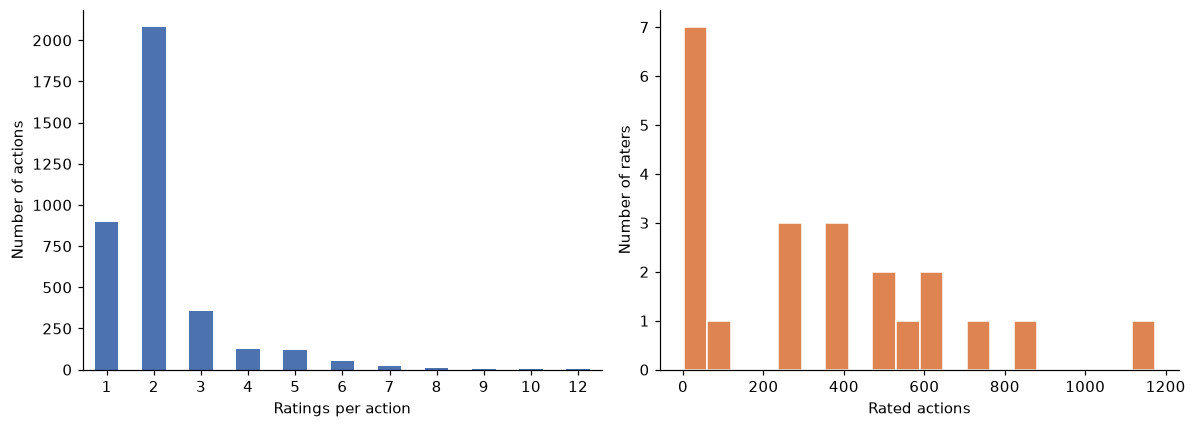

Ratings per action:
n_ratings
1      898
2     2080
3      357
4      123
5      118
6       50
7       25
8        9
9        6
10       2
12       1
Name: count, dtype: int64

Cumulative ratings per action:
1 or more ratings     3669
2 or more ratings     2771
3 or more ratings      691
4 or more ratings      334
5 or more ratings      211
6 or more ratings       93
7 or more ratings       43
8 or more ratings       18
9 or more ratings        9
10 or more ratings       3
12 or more ratings       1
Name: count, dtype: int64

Ratings per rater:
rater_id
R22       2
R21       9
R20      13
R19      50
R16      52
R17      52
R18      55
R15      73
R13     254
R14     259
R12     264
R11     369
R10     383
R09     400
R06     520
R08     522
R07     547
R04     620
R05     633
R03     720
R02     873
R01    1174
Name: n_actions_rated, dtype: int64


In [3]:
ratings_per_action = df.groupby("action_id").size().rename("n_ratings")
ratings_per_rater = df.groupby("rater_id").size().rename("n_actions_rated")
ratings_cum = ratings_per_action.value_counts().sort_index(ascending=False).cumsum()
ratings_cum = ratings_cum.sort_index(ascending=True)
ratings_cum.index = [f"{x} or more ratings" for x in ratings_cum.index]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ratings_per_action.value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_xlabel("Ratings per action")
axes[0].set_ylabel("Number of actions")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)

axes[1].hist(ratings_per_rater.values, bins=min(20, n_raters), color="#DD8452", edgecolor="white")
axes[1].set_xlabel("Rated actions")
axes[1].set_ylabel("Number of raters")
fig.tight_layout()
plt.show()

print("Ratings per action:")
print(ratings_per_action.value_counts().sort_index())
print("\nCumulative ratings per action:")
print(ratings_cum)

print("\nRatings per rater:")
print(ratings_per_rater.sort_values())

In [4]:
RESULTS_TABLES = PROJECT_ROOT / "results" / "tables"
RESULTS_TABLES.mkdir(parents=True, exist_ok=True)

n_one = int((ratings_per_action == 1).sum())
n_two = int((ratings_per_action == 2).sum())
n_three_plus = int((ratings_per_action >= 3).sum())
k_mean = float(ratings_per_action.mean())
k_harmonic_all = float(len(ratings_per_action) / (1.0 / ratings_per_action).sum())
sample_ratings_per_action = pd.DataFrame({
    "quantity": ["n_ratings", "n_actions", "n_raters",
                 "n_actions_1_rating", "n_actions_2_ratings", "n_actions_3plus_ratings",
                 "share_actions_1_rating", "share_actions_2_ratings", "share_actions_3plus_ratings",
                 "max_ratings_per_action", "mean_ratings_per_action", "harmonic_mean_ratings_per_action",
                 "median_ratings_per_rater", "min_ratings_per_rater", "max_ratings_per_rater"],
    "value": [n_ratings, n_actions, n_raters,
              n_one, n_two, n_three_plus,
              n_one / n_actions, n_two / n_actions, n_three_plus / n_actions,
              int(ratings_per_action.max()), k_mean, k_harmonic_all,
              float(ratings_per_rater.median()), int(ratings_per_rater.min()), int(ratings_per_rater.max())],
})
sample_ratings_per_action.to_csv(RESULTS_TABLES / "sample_ratings_per_action.csv", index=False)

In [5]:
#| label: tbl-overview-ratings-per-action
#| tbl-cap: "Number of actions by number of ratings received, with the mean and harmonic mean number of ratings per action."
show_table(sample_ratings_per_action)

| quantity                         |    value |
|:---------------------------------|---------:|
| n_ratings                        | 7844.000 |
| n_actions                        | 3669.000 |
| n_raters                         |   22.000 |
| n_actions_1_rating               |  898.000 |
| n_actions_2_ratings              | 2080.000 |
| n_actions_3plus_ratings          |  691.000 |
| share_actions_1_rating           |    0.245 |
| share_actions_2_ratings          |    0.567 |
| share_actions_3plus_ratings      |    0.188 |
| max_ratings_per_action           |   12.000 |
| mean_ratings_per_action          |    2.138 |
| harmonic_mean_ratings_per_action |    1.726 |
| median_ratings_per_rater         |  316.500 |
| min_ratings_per_rater            |    2.000 |
| max_ratings_per_rater            | 1174.000 |

## 4. Connectivity of the rater-action design

Rater severity/leniency can only be told apart from true differences
between actions if raters are linked, directly or indirectly, through
shared actions. We build the rater-action bipartite graph and check how
connected it currently is, and how much overlap each pair of raters has.

In [6]:
B = nx.Graph()
B.add_nodes_from(df["action_id"].unique(), bipartite="action")
B.add_nodes_from(("R::" + df["rater_id"]).unique(), bipartite="rater")
B.add_edges_from(zip(df["action_id"], "R::" + df["rater_id"]))

components = sorted(nx.connected_components(B), key=len, reverse=True)
comp_summary = []
for i, comp in enumerate(components):
    action_nodes = [n for n in comp if not str(n).startswith("R::")]
    rater_nodes = [str(n)[3:] for n in comp if str(n).startswith("R::")]
    comp_summary.append({
        "component_id": i, "n_actions": len(action_nodes),
        "n_raters": len(rater_nodes), "raters": ", ".join(sorted(rater_nodes)),
    })
comp_summary_df = pd.DataFrame(comp_summary)
print(f"Number of connected components: {len(components)}")
comp_summary_df

Number of connected components: 1


,component_id,n_actions,n_raters,raters
0,0,3669,22,"R01, R02, R03, R04, R05, R06, R07, R08, R09, R..."


In [7]:
rater_ids_sorted = sorted(df["rater_id"].unique())
n = len(rater_ids_sorted)
rater_idx = {r: i for i, r in enumerate(rater_ids_sorted)}

overlap = np.zeros((n, n), dtype=int)
for raters_for_action in df.groupby("action_id")["rater_id"].apply(list):
    idxs = sorted(set(rater_idx[r] for r in raters_for_action))
    for a in range(len(idxs)):
        for b in range(a + 1, len(idxs)):
            overlap[idxs[a], idxs[b]] += 1
            overlap[idxs[b], idxs[a]] += 1

overlap_df = pd.DataFrame(overlap, index=rater_ids_sorted, columns=rater_ids_sorted)

# For each rater: overlap with their single best-connected partner.
best_partner_overlap = pd.Series(
    {r: overlap_df.loc[r].drop(r).max() for r in rater_ids_sorted},
    name="best_partner_overlap",
).sort_values()

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(overlap, cmap="viridis")
ax.set_xticks(range(n)); ax.set_xticklabels(rater_ids_sorted, rotation=90, fontsize=7)
ax.set_yticks(range(n)); ax.set_yticklabels(rater_ids_sorted, fontsize=7)
ax.set_xlabel("Rater"); ax.set_ylabel("Rater")
fig.colorbar(im, ax=ax, shrink=0.8, label="Jointly rated actions")
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "results" / "figures" / "fig_overview_rater_overlap.png", bbox_inches="tight", dpi=200)
fig.savefig(PROJECT_ROOT / "results" / "figures" / "fig_overview_rater_overlap.svg", bbox_inches="tight")
plt.close(fig)

print("Best-connected-partner overlap per rater (lower = more isolated):")
print(best_partner_overlap)

Best-connected-partner overlap per rater (lower = more isolated):
R22      1
R21      8
R20     10
R17     44
R18     46
R19     46
R16     52
R15     61
R14    108
R12    145
R09    147
R13    154
R10    157
R05    190
R08    191
R06    240
R04    257
R02    257
R03    329
R01    329
R11    357
R07    357
Name: best_partner_overlap, dtype: int64


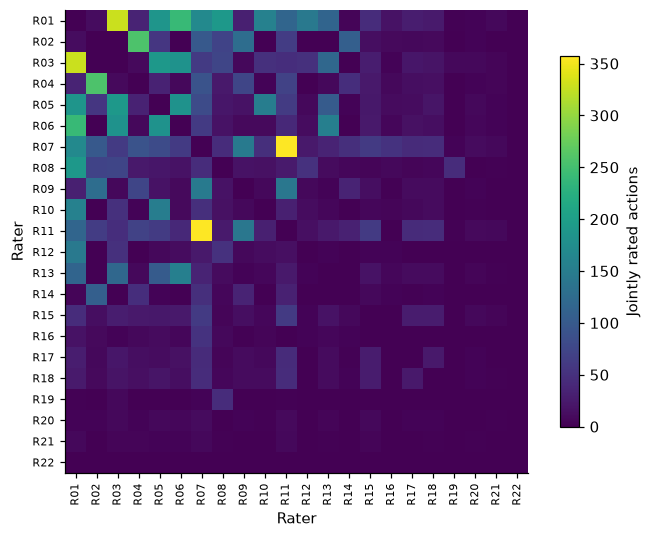

In [8]:
#| label: fig-overview-rater-overlap
#| fig-cap: "Number of jointly rated actions for each pair of raters."
fig

## 5. Design diagnostics

Properties of the rating design and of the raters' response styles, which do
not depend on any scoring approach.

In [9]:
from scipy import stats as sps

RESULTS_TABLES = PROJECT_ROOT / "results" / "tables"
RESULTS_FIGURES = PROJECT_ROOT / "results" / "figures"
for d in [RESULTS_TABLES, RESULTS_FIGURES]:
    d.mkdir(parents=True, exist_ok=True)

def save_fig(fig, name, caption=None):
    fig.savefig(RESULTS_FIGURES / f"{name}.png", bbox_inches="tight", dpi=200)
    fig.savefig(RESULTS_FIGURES / f"{name}.svg", bbox_inches="tight")
    if caption:
        (RESULTS_FIGURES / f"{name}_caption.txt").write_text(caption)

def save_table(df_table, name, index=False):
    df_table.to_csv(RESULTS_TABLES / f"{name}.csv", index=index)

### 5.1 Distribution of all ratings

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
df["rating_numeric"].value_counts().reindex(range(1, 8), fill_value=0).plot(kind="bar", ax=ax, color="#55A868")
ax.set_xlabel("Creativity rating (1 = not creative, 7 = very creative)")
ax.set_ylabel("Frequency")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
fig.tight_layout()
save_fig(fig, "fig_overview_rating_distribution",
         "Frequency of the seven rating categories across all ratings.")
plt.close(fig)

category_counts = df["rating_numeric"].value_counts().reindex(range(1, 8), fill_value=0)
category_table = pd.DataFrame({"category": range(1, 8), "n": category_counts.values,
                               "share": category_counts.values / len(df)})
save_table(category_table, "overview_category_frequencies")
print(category_table.to_string(index=False))

 category    n    share
        1 2034 0.259306
        2 2116 0.269760
        3 1471 0.187532
        4 1045 0.133223
        5  728 0.092810
        6  341 0.043473
        7  109 0.013896


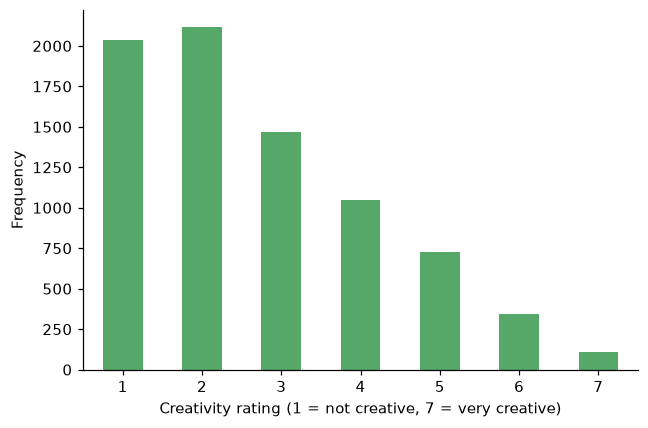

In [11]:
#| label: fig-overview-rating-distribution
#| fig-cap: "Frequency of the seven rating categories across all ratings."
fig

### 5.2 Rater response styles

Per rater: mean, median, SD, IQR, floor/ceiling rates, number of categories
used, entropy of the category distribution, and the shares of middle (3–5)
vs. extreme (1, 7) categories. These descriptives anticipate what the models
estimate formally: severity (the mean), scale width/discrimination (SD,
entropy), and central or extreme tendency.

In [12]:
def rater_summary(g):
    vals = g["rating_numeric"]
    n_cat = vals.nunique()
    p_extreme = vals.isin([1, 7]).mean()
    p_central = vals.isin([3, 4, 5]).mean()
    probs = vals.value_counts(normalize=True)
    entropy = -(probs * np.log(probs.clip(lower=1e-12))).sum()
    return pd.Series({
        "n_ratings": len(vals),
        "n_actions": g["action_id"].nunique(),
        "mean": vals.mean(),
        "median": vals.median(),
        "sd": vals.std(),
        "iqr": vals.quantile(0.75) - vals.quantile(0.25),
        "n_categories_used": n_cat,
        "entropy": entropy,
        "floor_rate": (vals == 1).mean(),
        "ceiling_rate": (vals == 7).mean(),
        "extreme_category_rate": p_extreme,
        "central_category_rate": p_central,
    })

rater_desc = df.groupby("rater_id").apply(rater_summary, include_groups=False).reset_index()
rater_desc = rater_desc.sort_values("mean").reset_index(drop=True)
save_table(rater_desc, "rater_descriptive_statistics")
rater_desc

,rater_id,n_ratings,n_actions,mean,median,sd,iqr,n_categories_used,entropy,floor_rate,ceiling_rate,extreme_category_rate,central_category_rate
0,R06,520.0,520.0,1.759615,1.0,1.111294,1.0,6.0,1.190539,0.578846,0.000000,0.578846,0.192308
1,R17,52.0,52.0,2.076923,2.0,1.296241,2.0,5.0,1.367338,0.480769,0.000000,0.480769,0.326923
2,R01,1174.0,1174.0,2.163543,2.0,1.021758,2.0,6.0,1.358086,0.287053,0.000000,0.287053,0.315162
3,R14,259.0,259.0,2.220077,2.0,1.358943,2.0,7.0,1.496399,0.405405,0.007722,0.413127,0.312741
4,R11,369.0,369.0,2.333333,2.0,1.396813,2.0,7.0,1.531914,0.344173,0.002710,0.346883,0.308943
5,R07,547.0,547.0,2.404022,2.0,1.406234,2.0,7.0,1.579651,0.334552,0.003656,0.338208,0.352834
6,R05,633.0,633.0,2.715640,2.0,1.554299,3.0,7.0,1.699955,0.251185,0.018957,0.270142,0.382306
7,R03,720.0,720.0,2.750000,3.0,1.401866,2.0,6.0,1.642639,0.223611,0.000000,0.223611,0.493056
8,R04,620.0,620.0,2.820968,2.0,1.628268,3.0,7.0,1.715283,0.264516,0.008065,0.272581,0.404839
9,R10,383.0,383.0,2.997389,3.0,1.311445,2.0,7.0,1.563593,0.065274,0.005222,0.070496,0.488251


In [13]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes[0, 0].hist(rater_desc["mean"], bins=20, color="#4C72B0")
axes[0, 0].set_xlabel("Rater mean rating"); axes[0, 0].set_ylabel("Number of raters")
axes[0, 1].hist(rater_desc["sd"], bins=20, color="#DD8452")
axes[0, 1].set_xlabel("Rater SD of ratings"); axes[0, 1].set_ylabel("Number of raters")
axes[1, 0].hist(rater_desc["n_categories_used"], bins=np.arange(1, 9) - 0.5, color="#55A868", edgecolor="white")
axes[1, 0].set_xticks(range(1, 8))
axes[1, 0].set_xlabel("Number of categories used (of 7)"); axes[1, 0].set_ylabel("Number of raters")
axes[1, 1].scatter(rater_desc["extreme_category_rate"], rater_desc["central_category_rate"],
                    s=20 + rater_desc["n_ratings"] / 5, alpha=0.7, color="#C44E52")
axes[1, 1].set_xlabel("Share of extreme categories (1, 7)")
axes[1, 1].set_ylabel("Share of middle categories (3-5)")
from matplotlib.ticker import MaxNLocator
for ax in [axes[0, 0], axes[0, 1], axes[1, 0]]:
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
for ax, letter in zip(axes.flat, "ABCD"):
    ax.text(-0.12, 1.04, letter, transform=ax.transAxes, fontweight="bold", fontsize=12)
fig.tight_layout()
save_fig(fig, "fig_overview_rater_response_styles",
         "Descriptive rater response styles: (A) rater means, (B) rater standard deviations, "
         "(C) number of rating categories used, (D) share of extreme (1, 7) versus middle (3-5) "
         "categories; point size is proportional to the number of ratings.")
plt.close(fig)

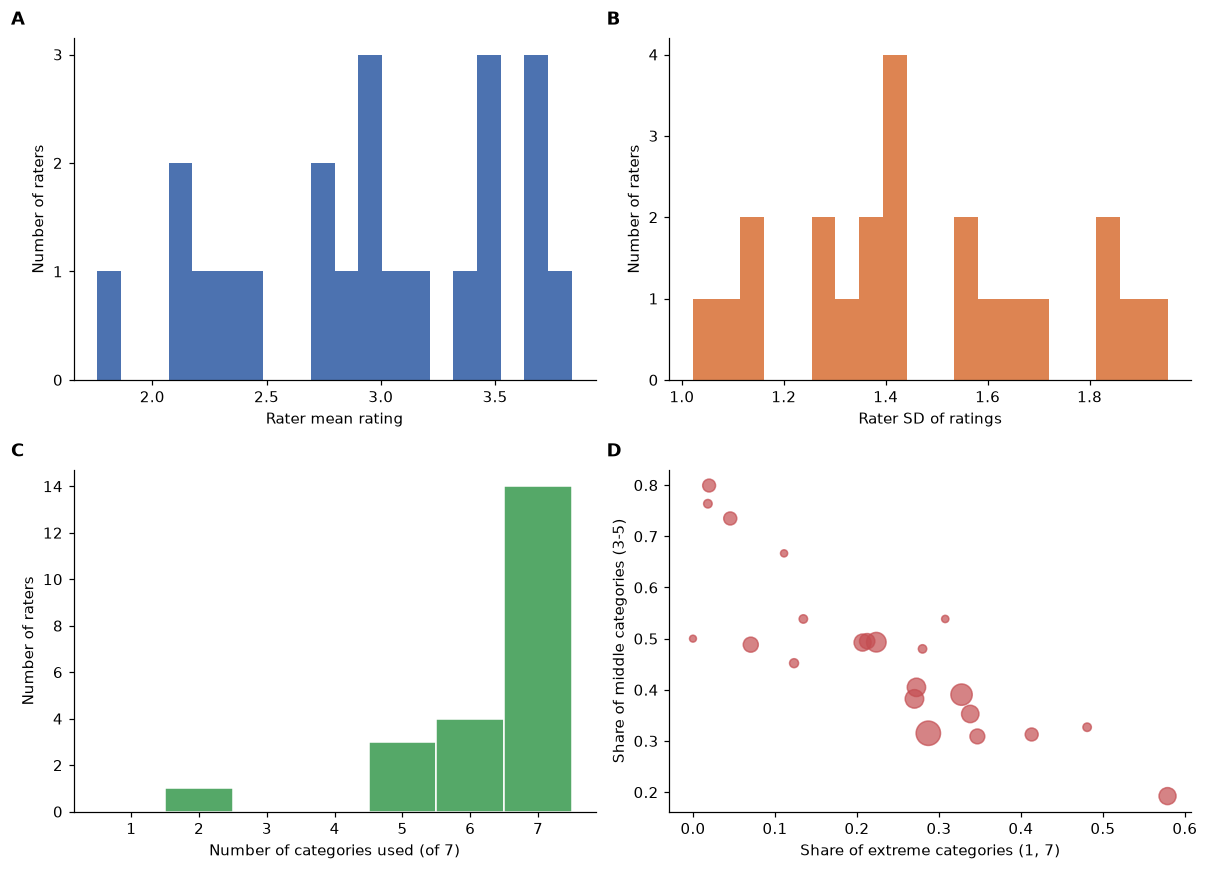

In [14]:
#| label: fig-overview-rater-response-styles
#| fig-cap: "Descriptive rater response styles: (A) rater means, (B) rater standard deviations, (C) number of rating categories used, (D) share of extreme (1, 7) versus middle (3-5) categories; point size is proportional to the number of ratings."
fig

### 5.3 Degree distributions and component summary

Degrees in the bipartite rater–action graph from Section 4: raters per action
and actions per rater.

In [15]:
action_degree = ratings_per_action
rater_degree = ratings_per_rater

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(action_degree.values, bins=np.arange(1, action_degree.max() + 2) - 0.5,
             color="#4C72B0", edgecolor="white")
axes[0].set_xlabel("Raters per action"); axes[0].set_ylabel("Number of actions")
axes[0].set_xticks(range(1, action_degree.max() + 1))
axes[1].hist(rater_degree.values, bins=20, color="#DD8452", edgecolor="white")
axes[1].set_xlabel("Actions per rater"); axes[1].set_ylabel("Number of raters")
from matplotlib.ticker import MaxNLocator
axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))
for ax, letter in zip(axes, "AB"):
    ax.text(-0.1, 1.04, letter, transform=ax.transAxes, fontweight="bold", fontsize=12)
fig.tight_layout()
save_fig(fig, "fig_overview_degree_distributions",
         "Degree distributions of the bipartite rater-action design: (A) number of raters per "
         "action, (B) number of actions per rater.")
plt.close(fig)

save_table(comp_summary_df, "connectivity_component_summary")
print(f"Raters with <= 2 rated actions: {(rater_degree <= 2).sum()}")

Raters with <= 2 rated actions: 1


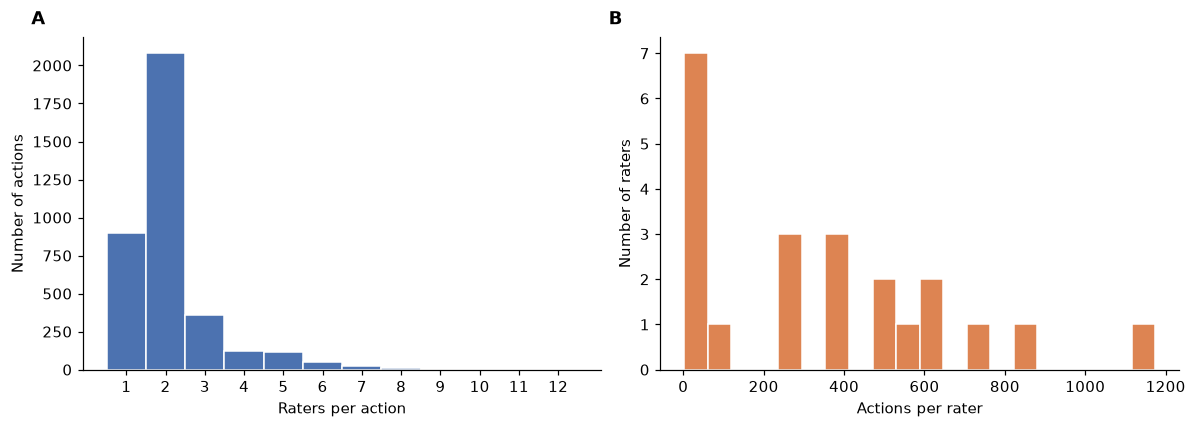

In [16]:
#| label: fig-overview-degree-distributions
#| fig-cap: "Degree distributions of the bipartite rater-action design: (A) number of raters per action, (B) number of actions per rater."
fig